# Demo & Evaluation — Demand Classifier + Dead-Stock Predictor

This notebook walks through the two models in `ML models/`:

1. **Setup** — load features, labels, models
2. **Data look** — feature table + label distribution
3. **Demand classifier** — metrics, confusion matrix, feature importances, examples
4. **Dead-stock predictor** — metrics, confusion matrix, ROC, examples
5. **Robustness evaluation** — re-train with rule-defining features hidden
6. **Live API smoke test** — exercise every endpoint via `TestClient`

Run order: `Cell → Run All`. Training/evaluation cells re-run from scratch so the notebook is self-contained.

## 1. Setup

In [1]:
import sys, json
from pathlib import Path

# Make the `src` package importable when the notebook lives in ML models/notebooks/
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
print("Project ML root:", ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, roc_auc_score)

from src.data_loader import build_feature_table, FEATURE_COLUMNS
from src.labels import label_demand, label_dead_stock, DEMAND_CLASSES
from src import train_demand, train_dead_stock, evaluate as robust_eval
from src.predict import (predict_by_code, predict_batch,
                         predict_demand_from_features,
                         predict_dead_stock_from_features)

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

Project ML root: D:\Projects\Grad Project\inventory-management-system\ML models


## 2. Feature table & labels

In [2]:
feats = build_feature_table()
print("shape:", feats.shape)
feats.head()

shape: (2428, 15)


,الكود,اسم الصنف,total_sales,total_stock,branches_with_sales,branches_with_stock,max_branch_sales,max_branch_stock,sales_concentration,stock_to_sales_ratio,sell_through,category,cost_price,retail_price,margin_pct
0,10000019,لعبة سلايم 60,19.0,13.0,2,2,15.0,7.0,0.789474,0.684211,0.59375,لعب,27.14,60.0,0.547667
1,1000006,مبرد معدن,1.0,1.0,1,1,1.0,1.0,1.000000,1.000000,0.50000,أدوات تجميل,19.33,40.0,0.516750
2,1000012,قلم كحل flormar,7.0,18.0,2,1,5.0,18.0,0.714286,2.571429,0.28000,أدوات تجميل,7.61,35.0,0.782571
3,1000062,سبحة الالكترونية,7.0,43.0,3,3,5.0,32.0,0.714286,6.142857,0.14000,منوعات,8.00,30.0,0.733333
4,1000064,لعبة كونكت 4,3.0,0.0,2,0,2.0,0.0,0.666667,0.000000,1.00000,لعب,72.49,170.0,0.573588


In [3]:
feats[FEATURE_COLUMNS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
total_sales,2428.0,5.58,21.74,0.0,1.00,2.00,4.00,564.1
total_stock,2428.0,16.10,61.30,0.0,1.00,3.00,11.00,1486.0
branches_with_sales,2428.0,1.50,1.22,0.0,1.00,1.00,2.00,8.0
branches_with_stock,2428.0,1.22,1.29,0.0,1.00,1.00,1.00,8.0
max_branch_sales,2428.0,3.44,8.80,0.0,1.00,1.00,3.00,184.1
max_branch_stock,2428.0,9.50,25.33,0.0,1.00,3.00,9.00,516.0
sales_concentration,2428.0,0.84,0.28,0.0,0.67,1.00,1.00,1.0
stock_to_sales_ratio,2428.0,7.80,22.80,0.0,0.33,1.67,4.14,223.0
sell_through,2428.0,0.47,0.34,0.0,0.19,0.38,0.75,1.0
cost_price,2428.0,89.41,115.76,0.0,24.17,50.70,106.14,1595.0


In [4]:
y_demand = label_demand(feats)
y_dead   = label_dead_stock(feats)

print("Demand class distribution:")
print(y_demand.value_counts().reindex(DEMAND_CLASSES))

print("\nDead-stock distribution:")
print(y_dead.value_counts().rename({0: 'not_dead', 1: 'dead'}))
print("positive rate: %.2f%%" % (100 * y_dead.mean()))

Demand class distribution:
slow      1559
medium     429
fast       440
Name: count, dtype: int64

Dead-stock distribution:
not_dead    2309
dead         119
Name: count, dtype: int64
positive rate: 4.90%


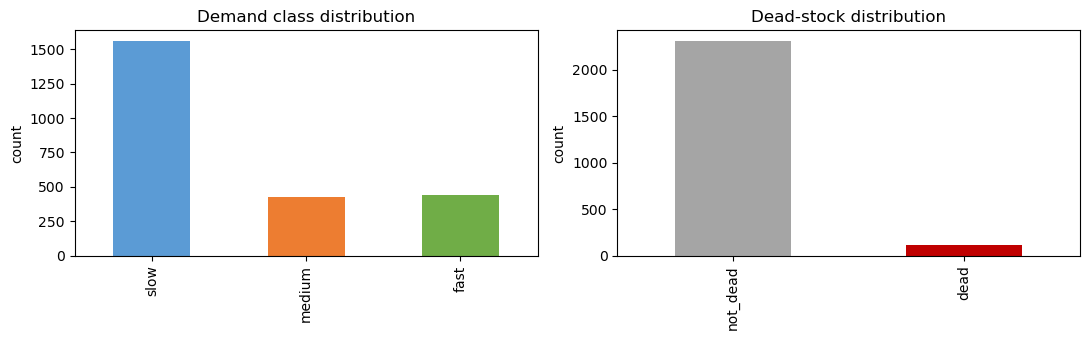

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
y_demand.value_counts().reindex(DEMAND_CLASSES).plot(kind='bar', ax=axes[0],
                                                     color=['#5b9bd5', '#ed7d31', '#70ad47'])
axes[0].set_title('Demand class distribution'); axes[0].set_ylabel('count')
y_dead.map({0:'not_dead',1:'dead'}).value_counts().plot(kind='bar', ax=axes[1],
                                                         color=['#a5a5a5','#c00000'])
axes[1].set_title('Dead-stock distribution'); axes[1].set_ylabel('count')
plt.tight_layout(); plt.show()

## 3. Demand classifier

In [6]:
demand_metrics = train_demand.train()
print("Macro F1:", demand_metrics['macro_f1'])
print("Accuracy:", demand_metrics['accuracy'])
pd.DataFrame(demand_metrics['per_class']).T.round(3)

Macro F1: 1.0
Accuracy: 1.0


,precision,recall,f1-score,support
slow,1.0,1.0,1.0,390.0
medium,1.0,1.0,1.0,107.0
fast,1.0,1.0,1.0,110.0


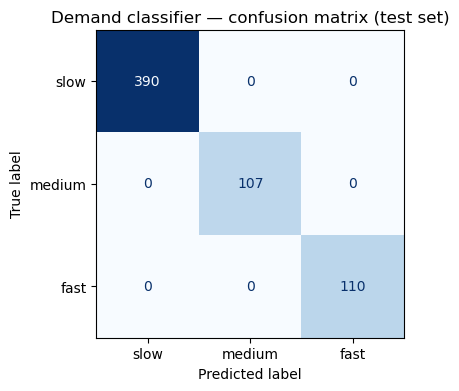

In [7]:
cm = np.array(demand_metrics['confusion_matrix'])
disp = ConfusionMatrixDisplay(cm, display_labels=DEMAND_CLASSES)
fig, ax = plt.subplots(figsize=(4.5, 4))
disp.plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Demand classifier — confusion matrix (test set)')
plt.show()

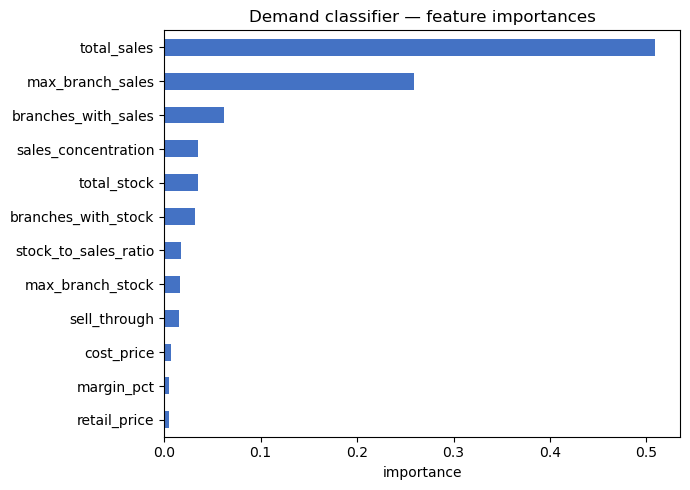

In [8]:
imp = pd.Series(demand_metrics['feature_importances']).sort_values()
imp.plot(kind='barh', figsize=(7, 5), color='#4472c4')
plt.title('Demand classifier — feature importances')
plt.xlabel('importance'); plt.tight_layout(); plt.show()

### Live demand predictions on real products

In [9]:
sample_codes = feats['الكود'].astype(str).head(5).tolist()
rows = []
for code in sample_codes:
    r = predict_by_code(code)
    rows.append({
        'code': r['code'],
        'name': r['name'],
        'total_sales': r['features']['total_sales'],
        'total_stock': r['features']['total_stock'],
        'demand_label': r['demand']['label'],
        **{f"p_{k}": v for k, v in r['demand']['probabilities'].items()},
    })
pd.DataFrame(rows)

,code,name,total_sales,total_stock,demand_label,p_fast,p_medium,p_slow
0,10000019,لعبة سلايم 60,19.0,13.0,fast,0.9963,0.0037,0.0000
1,1000006,مبرد معدن,1.0,1.0,slow,0.0000,0.0000,1.0000
2,1000012,قلم كحل flormar,7.0,18.0,fast,0.9675,0.0292,0.0033
3,1000062,سبحة الالكترونية,7.0,43.0,fast,0.9905,0.0095,0.0000
4,1000064,لعبة كونكت 4,3.0,0.0,medium,0.0087,0.9861,0.0052


In [10]:
print("Healthy fast-mover (raw features):")
print(json.dumps(predict_demand_from_features({
    'total_sales': 50, 'total_stock': 10, 'branches_with_sales': 5,
    'branches_with_stock': 3, 'max_branch_sales': 20, 'max_branch_stock': 5,
    'sales_concentration': 0.4, 'stock_to_sales_ratio': 0.2, 'sell_through': 0.83,
    'cost_price': 30, 'retail_price': 60, 'margin_pct': 0.5,
}), indent=2))

print("\nLow-volume single-branch product:")
print(json.dumps(predict_demand_from_features({
    'total_sales': 1, 'total_stock': 50, 'branches_with_sales': 1,
    'branches_with_stock': 5, 'max_branch_sales': 1, 'max_branch_stock': 20,
    'sales_concentration': 1.0, 'stock_to_sales_ratio': 50, 'sell_through': 0.02,
    'cost_price': 30, 'retail_price': 60, 'margin_pct': 0.5,
}), indent=2))

Healthy fast-mover (raw features):
{
  "label": "fast",
  "probabilities": {
    "fast": 0.9922,
    "medium": 0.0078,
    "slow": 0.0
  }
}

Low-volume single-branch product:
{
  "label": "slow",
  "probabilities": {
    "fast": 0.015,
    "medium": 0.1135,
    "slow": 0.8716
  }
}


## 4. Dead-stock predictor

In [11]:
dead_metrics = train_dead_stock.train()
print("F1 (dead):", dead_metrics['f1_dead_stock'])
print("ROC-AUC:  ", dead_metrics['roc_auc'])
print("Accuracy: ", dead_metrics['accuracy'])
pd.DataFrame(dead_metrics['per_class']).T.round(3)

F1 (dead): 1.0
ROC-AUC:   1.0
Accuracy:  1.0


,precision,recall,f1-score,support
not_dead,1.0,1.0,1.0,577.0
dead,1.0,1.0,1.0,30.0


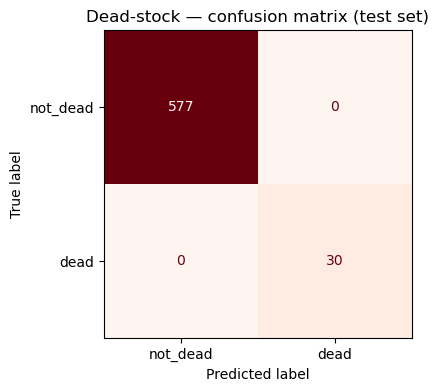

In [12]:
cm = np.array(dead_metrics['confusion_matrix'])
disp = ConfusionMatrixDisplay(cm, display_labels=['not_dead', 'dead'])
fig, ax = plt.subplots(figsize=(4.5, 4))
disp.plot(ax=ax, cmap='Reds', colorbar=False)
ax.set_title('Dead-stock — confusion matrix (test set)')
plt.show()

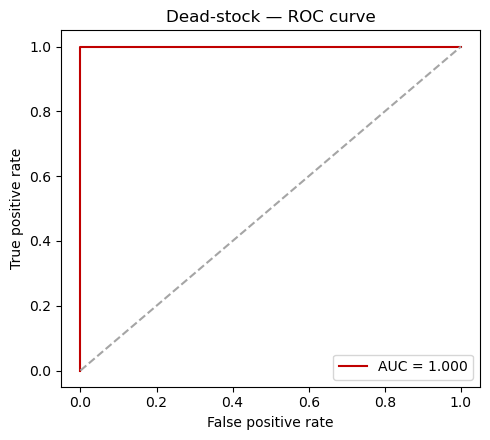

In [13]:
# ROC curve, recomputed live so we have probabilities
import joblib
from sklearn.model_selection import train_test_split

bundle = joblib.load(ROOT / 'artifacts' / 'dead_stock_classifier.joblib')
X = feats[FEATURE_COLUMNS].fillna(0.0)
Xtr, Xte, ytr, yte = train_test_split(X, y_dead, test_size=0.25, random_state=42, stratify=y_dead)
yproba = bundle['pipeline'].predict_proba(Xte)[:, 1]
fpr, tpr, _ = roc_curve(yte, yproba)
auc = roc_auc_score(yte, yproba)

plt.figure(figsize=(5, 4.5))
plt.plot(fpr, tpr, label=f'AUC = {auc:.3f}', color='#c00000')
plt.plot([0,1],[0,1], '--', color='#a5a5a5')
plt.xlabel('False positive rate'); plt.ylabel('True positive rate')
plt.title('Dead-stock — ROC curve'); plt.legend(); plt.tight_layout(); plt.show()

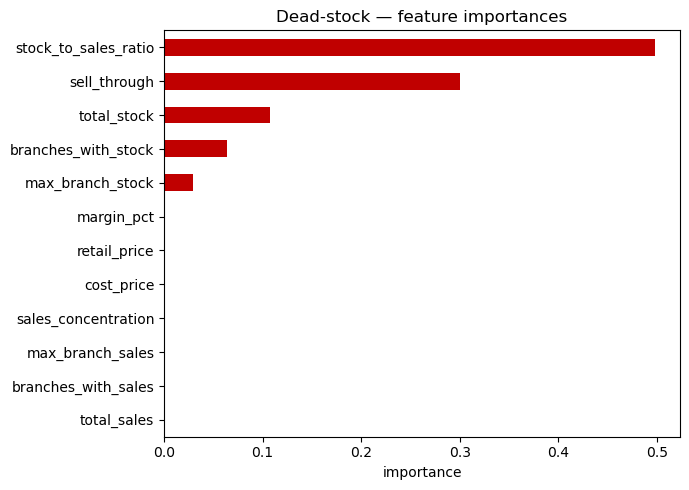

In [14]:
imp = pd.Series(dead_metrics['feature_importances']).sort_values()
imp.plot(kind='barh', figsize=(7, 5), color='#c00000')
plt.title('Dead-stock — feature importances')
plt.xlabel('importance'); plt.tight_layout(); plt.show()

### Live dead-stock predictions on real products

Pick a few products that the rule labels as dead-stock and check the model's probability.

In [15]:
dead_codes = feats.loc[y_dead == 1, 'الكود'].astype(str).head(5).tolist()
rows = []
for code in dead_codes:
    r = predict_by_code(code)
    rows.append({
        'code': r['code'], 'name': r['name'],
        'sales': r['features']['total_sales'],
        'stock': r['features']['total_stock'],
        'sell_through': r['features']['sell_through'],
        'demand': r['demand']['label'],
        'dead_prob': r['dead_stock']['probability'],
        'is_dead': r['dead_stock']['is_dead_stock'],
    })
pd.DataFrame(rows)

,code,name,sales,stock,sell_through,demand,dead_prob,is_dead
0,1000090,كريم العود الملكى,1.0,29.0,0.033333,slow,1.0,True
1,1000703,روج سحرى YANFDI,1.0,30.0,0.032258,slow,1.0,True
2,1000746,لعبة حصالة الكتورنية,0.0,2.0,0.000000,slow,1.0,True
3,1001244,روج MN L548,0.0,1.0,0.000000,slow,1.0,True
4,1001252,روج stick flomar 8013,0.0,2.0,0.000000,slow,1.0,True


In [16]:
print("Idle stock (raw features):")
print(json.dumps(predict_dead_stock_from_features({
    'total_sales': 0, 'total_stock': 30, 'branches_with_sales': 0,
    'branches_with_stock': 4, 'max_branch_sales': 0, 'max_branch_stock': 10,
    'sales_concentration': 0, 'stock_to_sales_ratio': 130, 'sell_through': 0,
    'cost_price': 30, 'retail_price': 60, 'margin_pct': 0.5,
}), indent=2))

print("\nHealthy mover (raw features):")
print(json.dumps(predict_dead_stock_from_features({
    'total_sales': 80, 'total_stock': 20, 'branches_with_sales': 8,
    'branches_with_stock': 6, 'max_branch_sales': 25, 'max_branch_stock': 8,
    'sales_concentration': 0.31, 'stock_to_sales_ratio': 0.25, 'sell_through': 0.80,
    'cost_price': 30, 'retail_price': 60, 'margin_pct': 0.5,
}), indent=2))

Idle stock (raw features):
{
  "is_dead_stock": true,
  "probability": 1.0
}

Healthy mover (raw features):
{
  "is_dead_stock": false,
  "probability": 0.0
}


## 5. Robustness evaluation

Standard hold-out scores 1.0 because labels are deterministic over visible features. The honest test is: **hide those features and see how well the rest reconstruct the label.**

In [17]:
rob = robust_eval.run()

print("Demand robustness — features hidden:", rob['demand_robust']['hidden'])
print(f"  macro F1 = {rob['demand_robust']['macro_f1']}, accuracy = {rob['demand_robust']['accuracy']}")
demand_robust_df = pd.DataFrame(rob['demand_robust']['per_class']).T.round(3)
demand_robust_df

Demand robustness — features hidden: ['total_sales', 'max_branch_sales']
  macro F1 = 0.8663, accuracy = 0.9094


,precision,recall,f1-score,support
slow,0.949,0.964,0.957,390.0
medium,0.818,0.757,0.786,107.0
fast,0.848,0.864,0.856,110.0


In [18]:
print("Dead-stock robustness — features hidden:", rob['dead_stock_robust']['hidden'])
print(f"  F1 (dead) = {rob['dead_stock_robust']['f1_dead']}, AUC = {rob['dead_stock_robust']['roc_auc']}, accuracy = {rob['dead_stock_robust']['accuracy']}")
dead_robust_df = pd.DataFrame(rob['dead_stock_robust']['per_class']).T.round(3)
dead_robust_df

Dead-stock robustness — features hidden: ['total_sales', 'total_stock', 'stock_to_sales_ratio', 'sell_through']
  F1 (dead) = 0.9667, AUC = 0.9999, accuracy = 0.9967


,precision,recall,f1-score,support
not_dead,0.998,0.998,0.998,577.0
dead,0.967,0.967,0.967,30.0


In [19]:
summary = pd.DataFrame([
    {'model': 'demand', 'eval': 'standard',  'metric': 'macro F1', 'value': demand_metrics['macro_f1']},
    {'model': 'demand', 'eval': 'robust',    'metric': 'macro F1', 'value': rob['demand_robust']['macro_f1']},
    {'model': 'dead_stock', 'eval': 'standard', 'metric': 'F1 (dead)', 'value': dead_metrics['f1_dead_stock']},
    {'model': 'dead_stock', 'eval': 'robust',   'metric': 'F1 (dead)', 'value': rob['dead_stock_robust']['f1_dead']},
    {'model': 'dead_stock', 'eval': 'standard', 'metric': 'ROC-AUC',  'value': dead_metrics['roc_auc']},
    {'model': 'dead_stock', 'eval': 'robust',   'metric': 'ROC-AUC',  'value': rob['dead_stock_robust']['roc_auc']},
])
summary

,model,eval,metric,value
0,demand,standard,macro F1,1.0000
1,demand,robust,macro F1,0.8663
2,dead_stock,standard,F1 (dead),1.0000
3,dead_stock,robust,F1 (dead),0.9667
4,dead_stock,standard,ROC-AUC,1.0000
5,dead_stock,robust,ROC-AUC,0.9999


## 6. API smoke test (FastAPI TestClient)

Same calls a backend would make over HTTP. No server needs to be running.

In [20]:
from fastapi.testclient import TestClient
from api import app
client = TestClient(app)

print("GET /health         ->", client.get('/health').json())
codes = client.get('/codes/sample?limit=5').json()['codes']
print("GET /codes/sample   ->", codes)

GET /health         -> {'status': 'ok'}
GET /codes/sample   -> ['10000019', '1000006', '1000012', '1000062', '1000064']


In [21]:
r = client.get(f'/predict/by-code/{codes[0]}').json()
print(json.dumps(r, indent=2, ensure_ascii=False))

{
  "code": "10000019",
  "name": "لعبة سلايم 60",
  "found": true,
  "features": {
    "total_sales": 19.0,
    "total_stock": 13.0,
    "branches_with_sales": 2,
    "branches_with_stock": 2,
    "max_branch_sales": 15.0,
    "max_branch_stock": 7.0,
    "sales_concentration": 0.7894736842105263,
    "stock_to_sales_ratio": 0.6842105263157895,
    "sell_through": 0.59375,
    "cost_price": 27.14,
    "retail_price": 60.0,
    "margin_pct": 0.5476666666666666
  },
  "demand": {
    "label": "fast",
    "probabilities": {
      "fast": 0.9963,
      "medium": 0.0037,
      "slow": 0.0
    }
  },
  "dead_stock": {
    "is_dead_stock": false,
    "probability": 0.0
  }
}


In [22]:
batch_payload = {'codes': codes[:3] + dead_codes[:2]}
batch = client.post('/predict/batch', json=batch_payload).json()
rows = []
for item in batch['results']:
    if not item.get('found'):
        continue
    rows.append({
        'code': item['code'], 'name': item['name'],
        'demand': item['demand']['label'],
        'dead_prob': item['dead_stock']['probability'],
        'is_dead': item['dead_stock']['is_dead_stock'],
    })
pd.DataFrame(rows)

,code,name,demand,dead_prob,is_dead
0,10000019,لعبة سلايم 60,fast,0.0,False
1,1000006,مبرد معدن,slow,0.0,False
2,1000012,قلم كحل flormar,fast,0.0,False
3,1000090,كريم العود الملكى,slow,1.0,True
4,1000703,روج سحرى YANFDI,slow,1.0,True


In [23]:
metrics_resp = client.get('/metrics').json()
print("keys:", list(metrics_resp.keys()))
print("\ndemand summary:")
print(" macro_f1:", metrics_resp['demand']['macro_f1'])
print(" accuracy:", metrics_resp['demand']['accuracy'])
print("\ndead_stock summary:")
print(" f1_dead :", metrics_resp['dead_stock']['f1_dead_stock'])
print(" roc_auc :", metrics_resp['dead_stock']['roc_auc'])

keys: ['demand', 'dead_stock', 'robustness']

demand summary:
 macro_f1: 1.0
 accuracy: 1.0

dead_stock summary:
 f1_dead : 1.0
 roc_auc : 1.0


## 7. Hold-out test: synthetic unseen products

The training data covers 2,428 products. Here we test the models on a small
**hand-crafted set of unseen products** with known expected labels. Each row
represents a realistic inventory scenario — strong sellers, dead stock,
concentrated single-branch products, premium-margin items, and edge cases.

In [24]:
test_products = [
    # name, sales, stock, br_sales, br_stock, max_s, max_st, conc, ratio, sellthr, cost, retail, margin, expected_demand, expected_dead
    ('blockbuster toy across all branches',   500, 80, 10, 8, 90, 20, 0.18, 0.16, 0.86,  50,  120, 0.58, 'fast',   False),
    ('steady seller in 4 branches',            45, 25,  4, 3, 18, 10, 0.40, 0.56, 0.64,  30,   75, 0.60, 'medium', False),
    ('niche premium cosmetic',                  8, 12,  2, 2,  6,  8, 0.75, 1.50, 0.40,  80,  220, 0.64, 'medium', False),
    ('dead stock - never sold',                 0, 50,  0, 5,  0, 20, 0.00, 0.00, 0.00,  25,   60, 0.58, 'slow',   True),
    ('dead stock - almost no movement',         1, 80,  1, 4,  1, 30, 1.00, 80.0, 0.01,  40,   95, 0.58, 'slow',   True),
    ('dead stock - high-value idle',            0, 15,  0, 2,  0, 10, 0.00, 0.00, 0.00, 250,  600, 0.58, 'slow',   True),
    ('single-branch low volume',                3,  4,  1, 1,  3,  4, 1.00, 1.33, 0.43,  20,   45, 0.56, 'slow',   False),
    ('one-off sell-out',                        7,  0,  2, 0,  4,  0, 0.57, 0.00, 1.00,  35,   80, 0.56, 'medium', False),
    ('strong concentrated seller, 1 branch',  120, 30,  1, 1,120, 30, 1.00, 0.25, 0.80,  60,  150, 0.60, 'fast',   False),
    ('borderline medium/fast',                 28, 20,  3, 2, 12, 10, 0.43, 0.71, 0.58,  40,   95, 0.58, 'medium', False),
    ('low-margin commodity, healthy turn',     90, 15,  6, 4, 25,  6, 0.28, 0.17, 0.86,  18,   22, 0.18, 'fast',   False),
    ('luxury low-volume, healthy',             12,  8,  3, 2,  6,  4, 0.50, 0.67, 0.60, 400, 1100, 0.64, 'medium', False),
    ('barely-moved warehouse stock',            2,150,  1, 6,  2, 60, 1.00, 75.0, 0.01,  25,   55, 0.55, 'slow',   True),
    ('zero everything (new SKU not stocked)',   0,  0,  0, 0,  0,  0, 0.00, 0.00, 0.00,  30,   70, 0.57, 'slow',   False),
    ('cosmetic strong fast mover',            250, 40,  8, 5, 50, 12, 0.20, 0.16, 0.86,  60,  140, 0.57, 'fast',   False),
]

test_df = pd.DataFrame(test_products, columns=[
    'name', 'total_sales', 'total_stock',
    'branches_with_sales', 'branches_with_stock',
    'max_branch_sales', 'max_branch_stock',
    'sales_concentration', 'stock_to_sales_ratio', 'sell_through',
    'cost_price', 'retail_price', 'margin_pct',
    'expected_demand', 'expected_dead',
])
test_df

,name,total_sales,total_stock,branches_with_sales,branches_with_stock,max_branch_sales,max_branch_stock,sales_concentration,stock_to_sales_ratio,sell_through,cost_price,retail_price,margin_pct,expected_demand,expected_dead
0,blockbuster toy across all branches,500,80,10,8,90,20,0.18,0.16,0.86,50,120,0.58,fast,False
1,steady seller in 4 branches,45,25,4,3,18,10,0.40,0.56,0.64,30,75,0.60,medium,False
2,niche premium cosmetic,8,12,2,2,6,8,0.75,1.50,0.40,80,220,0.64,medium,False
3,dead stock - never sold,0,50,0,5,0,20,0.00,0.00,0.00,25,60,0.58,slow,True
4,dead stock - almost no movement,1,80,1,4,1,30,1.00,80.00,0.01,40,95,0.58,slow,True
5,dead stock - high-value idle,0,15,0,2,0,10,0.00,0.00,0.00,250,600,0.58,slow,True
6,single-branch low volume,3,4,1,1,3,4,1.00,1.33,0.43,20,45,0.56,slow,False
7,one-off sell-out,7,0,2,0,4,0,0.57,0.00,1.00,35,80,0.56,medium,False
8,"strong concentrated seller, 1 branch",120,30,1,1,120,30,1.00,0.25,0.80,60,150,0.60,fast,False
9,borderline medium/fast,28,20,3,2,12,10,0.43,0.71,0.58,40,95,0.58,medium,False


### 7a. Run both models on the unseen test set

In [25]:
rows = []
for _, row in test_df.iterrows():
    feat_payload = {c: row[c] for c in FEATURE_COLUMNS}
    d = predict_demand_from_features(feat_payload)
    s = predict_dead_stock_from_features(feat_payload)
    rows.append({
        'name': row['name'],
        'sales': row['total_sales'], 'stock': row['total_stock'],
        'expected_demand': row['expected_demand'],
        'pred_demand':     d['label'],
        'p_fast':   d['probabilities'].get('fast', 0),
        'p_medium': d['probabilities'].get('medium', 0),
        'p_slow':   d['probabilities'].get('slow', 0),
        'expected_dead': bool(row['expected_dead']),
        'pred_dead':     s['is_dead_stock'],
        'dead_prob':     s['probability'],
    })
results = pd.DataFrame(rows)
results

,name,sales,stock,expected_demand,pred_demand,p_fast,p_medium,p_slow,expected_dead,pred_dead,dead_prob
0,blockbuster toy across all branches,500,80,fast,fast,0.9978,0.0022,0.0000,False,False,0.0000
1,steady seller in 4 branches,45,25,medium,fast,1.0000,0.0000,0.0000,False,False,0.0000
2,niche premium cosmetic,8,12,medium,fast,0.9663,0.0337,0.0000,False,False,0.0000
3,dead stock - never sold,0,50,slow,slow,0.0489,0.1830,0.7681,True,False,0.0502
4,dead stock - almost no movement,1,80,slow,slow,0.0206,0.1069,0.8726,True,True,1.0000
5,dead stock - high-value idle,0,15,slow,slow,0.0186,0.0910,0.8904,True,False,0.0502
6,single-branch low volume,3,4,slow,medium,0.0000,0.9967,0.0033,False,False,0.0000
7,one-off sell-out,7,0,medium,fast,0.9353,0.0647,0.0000,False,False,0.0000
8,"strong concentrated seller, 1 branch",120,30,fast,fast,0.9939,0.0061,0.0000,False,False,0.0000
9,borderline medium/fast,28,20,medium,fast,0.9975,0.0025,0.0000,False,False,0.0000


### 7b. Match vs mismatch

In [26]:
results['demand_match'] = results['expected_demand'] == results['pred_demand']
results['dead_match']   = results['expected_dead']   == results['pred_dead']

demand_acc = results['demand_match'].mean()
dead_acc   = results['dead_match'].mean()
print(f'Demand classifier accuracy on unseen test set: {demand_acc:.0%} '
      f'({int(results["demand_match"].sum())}/{len(results)})')
print(f'Dead-stock predictor accuracy on unseen test set: {dead_acc:.0%} '
      f'({int(results["dead_match"].sum())}/{len(results)})')

def highlight(row):
    style = ['']*len(row)
    if not row['demand_match']:
        style[results.columns.get_loc('pred_demand')] = 'background-color:#fde0e0'
    if not row['dead_match']:
        style[results.columns.get_loc('pred_dead')]   = 'background-color:#fde0e0'
    return style

display_cols = ['name','sales','stock','expected_demand','pred_demand',
                'expected_dead','pred_dead','dead_prob','demand_match','dead_match']
results[display_cols].style.apply(highlight, axis=1)

Demand classifier accuracy on unseen test set: 60% (9/15)
Dead-stock predictor accuracy on unseen test set: 87% (13/15)


,name,sales,stock,expected_demand,pred_demand,expected_dead,pred_dead,dead_prob,demand_match,dead_match
0,blockbuster toy across all branches,500,80,fast,fast,False,False,0.000000,True,True
1,steady seller in 4 branches,45,25,medium,fast,False,False,0.000000,False,True
2,niche premium cosmetic,8,12,medium,fast,False,False,0.000000,False,True
3,dead stock - never sold,0,50,slow,slow,True,False,0.050200,True,False
4,dead stock - almost no movement,1,80,slow,slow,True,True,1.000000,True,True
5,dead stock - high-value idle,0,15,slow,slow,True,False,0.050200,True,False
6,single-branch low volume,3,4,slow,medium,False,False,0.000000,False,True
7,one-off sell-out,7,0,medium,fast,False,False,0.000000,False,True
8,"strong concentrated seller, 1 branch",120,30,fast,fast,False,False,0.000000,True,True
9,borderline medium/fast,28,20,medium,fast,False,False,0.000000,False,True


### 7c. Confusion matrices on the unseen test set

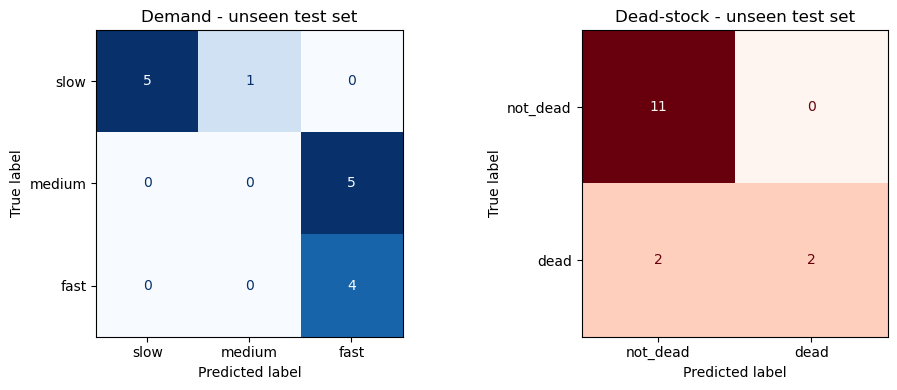

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

cm_d = confusion_matrix(results['expected_demand'], results['pred_demand'],
                        labels=DEMAND_CLASSES)
ConfusionMatrixDisplay(cm_d, display_labels=DEMAND_CLASSES).plot(
    ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Demand - unseen test set')

cm_s = confusion_matrix(results['expected_dead'], results['pred_dead'],
                        labels=[False, True])
ConfusionMatrixDisplay(cm_s, display_labels=['not_dead','dead']).plot(
    ax=axes[1], cmap='Reds', colorbar=False)
axes[1].set_title('Dead-stock - unseen test set')

plt.tight_layout(); plt.show()

In [28]:
print('=== Demand classifier ===')
print(classification_report(results['expected_demand'], results['pred_demand'],
                            labels=DEMAND_CLASSES, zero_division=0))

print('=== Dead-stock predictor ===')
print(classification_report(results['expected_dead'].astype(int),
                            results['pred_dead'].astype(int),
                            target_names=['not_dead','dead'], zero_division=0))

=== Demand classifier ===
              precision    recall  f1-score   support

        slow       1.00      0.83      0.91         6
      medium       0.00      0.00      0.00         5
        fast       0.44      1.00      0.62         4

    accuracy                           0.60        15
   macro avg       0.48      0.61      0.51        15
weighted avg       0.52      0.60      0.53        15

=== Dead-stock predictor ===
              precision    recall  f1-score   support

    not_dead       0.85      1.00      0.92        11
        dead       1.00      0.50      0.67         4

    accuracy                           0.87        15
   macro avg       0.92      0.75      0.79        15
weighted avg       0.89      0.87      0.85        15



### 7d. Inspect any mismatches

In [29]:
mismatches = results[~(results['demand_match'] & results['dead_match'])]
if mismatches.empty:
    print('No mismatches - both models matched the expected labels on every test row.')
else:
    print(f'{len(mismatches)} row(s) had at least one mismatch:')
mismatches[display_cols]

8 row(s) had at least one mismatch:


,name,sales,stock,expected_demand,pred_demand,expected_dead,pred_dead,dead_prob,demand_match,dead_match
1,steady seller in 4 branches,45,25,medium,fast,False,False,0.0000,False,True
2,niche premium cosmetic,8,12,medium,fast,False,False,0.0000,False,True
3,dead stock - never sold,0,50,slow,slow,True,False,0.0502,True,False
5,dead stock - high-value idle,0,15,slow,slow,True,False,0.0502,True,False
6,single-branch low volume,3,4,slow,medium,False,False,0.0000,False,True
7,one-off sell-out,7,0,medium,fast,False,False,0.0000,False,True
9,borderline medium/fast,28,20,medium,fast,False,False,0.0000,False,True
11,"luxury low-volume, healthy",12,8,medium,fast,False,False,0.0000,False,True


---
**Take-aways**

- Both models hit 1.0 on the standard hold-out — expected, since labels are deterministic over features the model sees. Treat that as a sanity check, not a generalization test.
- The robustness eval (rule-defining features hidden) is the honest read: demand macro F1 ≈ **0.87**, dead-stock F1 ≈ **0.97** / AUC **0.999**.
- The API surface mirrors what a backend will consume — `by-code`, `batch`, raw-feature endpoints, and a metrics endpoint that exposes the JSON reports.